In [ ]:
# 1. Imports & Configuration
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# 2. Load Dataset
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(DATA_PATH)

df.head()



(7043, 21)

## Business Questions

1. What is the overall customer churn rate?

2. Which customer segments have the highest churn rate?

3. Does customer tenure affect churn probability?

4. Does contract type influence churn?

5. Does monthly spending correlate with churn?

6. Which services are associated with higher customer retention?

7. Which payment methods are associated with higher churn?

8. Can we predict customers who are likely to churn?

9. Which customers should the business prioritize for retention campaigns?

In [ ]:
df.shape

(7043, 21)

### Dataset Overview

The dataset contains 7,043 customer records and 21 attributes
covering customer demographics, subscribed services,
account information, billing information, and churn status.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Initial Data Quality Observation

`TotalCharges` is currently represented as an object/string
rather than a numerical variable. This requires further
investigation before model training.

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["customerID"].duplicated().sum()

np.int64(0)

In [ ]:
missing = df.isnull().sum()

missing[missing > 0]

Series([], dtype: int64)

In [ ]:
for column in df.columns:
    print(f"\n--- {column} ---")
    print(df[column].unique()[:20])


--- customerID ---
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 '9763-GRSKD', '7469-LKBCI', '8091-TTVAX', '0280-XJGEX', '5129-JLPIS',
 '3655-SNQYZ', '8191-XWSZG', '9959-WOFKT', '4190-MFLUW', '4183-MYFRB']
Length: 20, dtype: str

--- gender ---
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

--- SeniorCitizen ---
[0 1]

--- Partner ---
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

--- Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- tenure ---
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30]

--- PhoneService ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- MultipleLines ---
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

--- InternetService ---
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

--- OnlineSecurity ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dty

In [ ]:
df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [ ]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

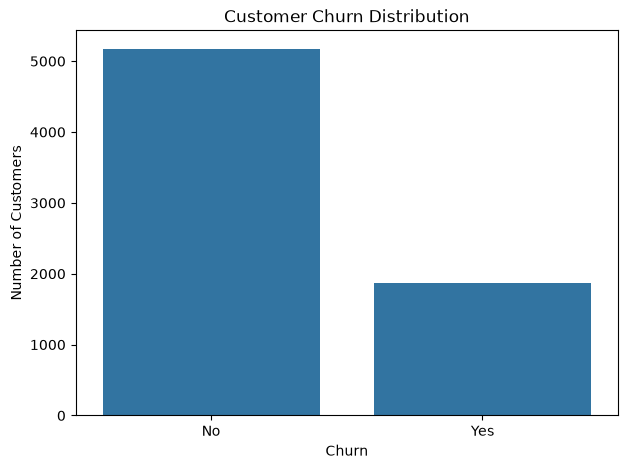

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
churn_rate = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_rate)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Finding

Approximately 26.5% of customers in the dataset have churned,
while approximately 73.5% have remained with the company.

### Business Implication

The dataset is moderately imbalanced because retained customers
significantly outnumber churned customers.

Therefore, model evaluation should not rely solely on accuracy.
Precision, recall, F1-score and ROC-AUC should also be considered.

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

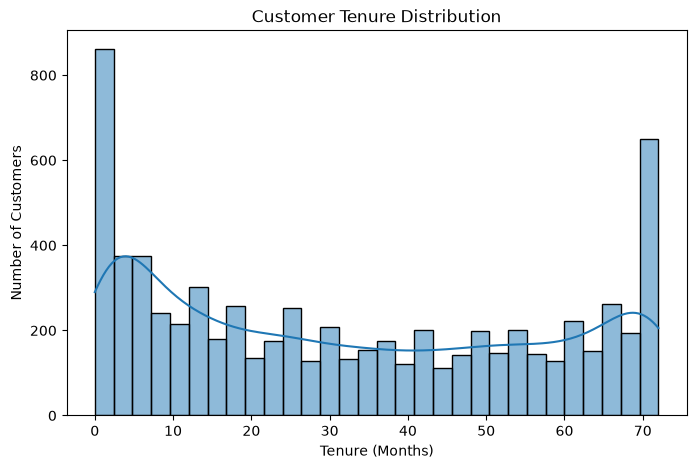

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

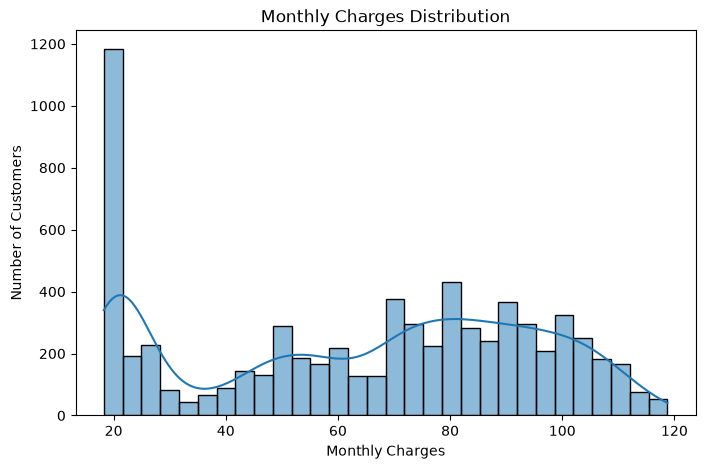

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=30,
    kde=True
)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

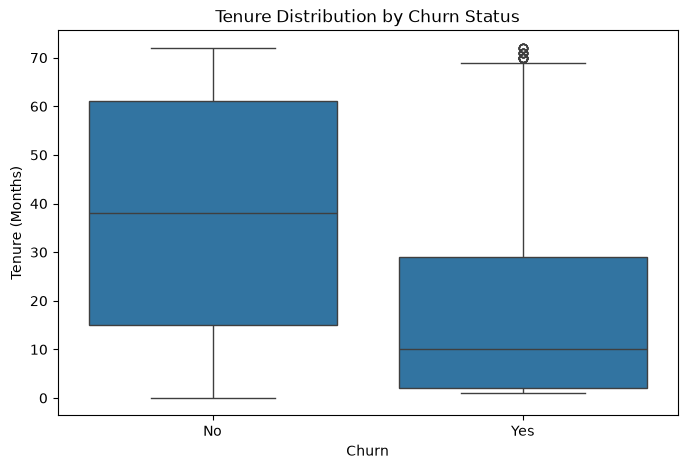

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

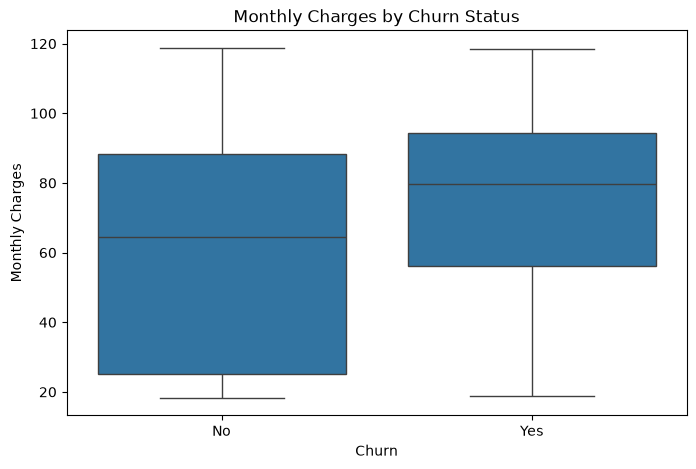

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [ ]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


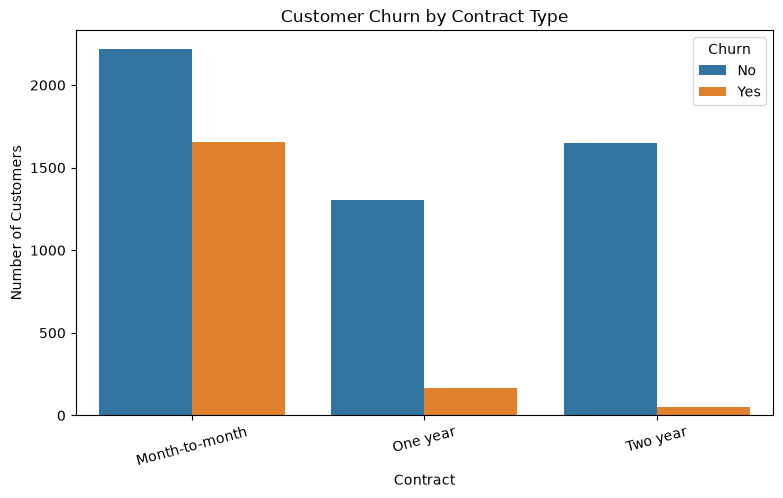

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

In [ ]:
def churn_rate_by_feature(dataframe, feature):
    return (
        pd.crosstab(
            dataframe[feature],
            dataframe["Churn"],
            normalize="index"
        ) * 100
    )
churn_rate_by_feature(df, "Contract")

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [ ]:
churn_rate_by_feature(df, "InternetService")

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [31]:
churn_rate_by_feature(df, "PaymentMethod")

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


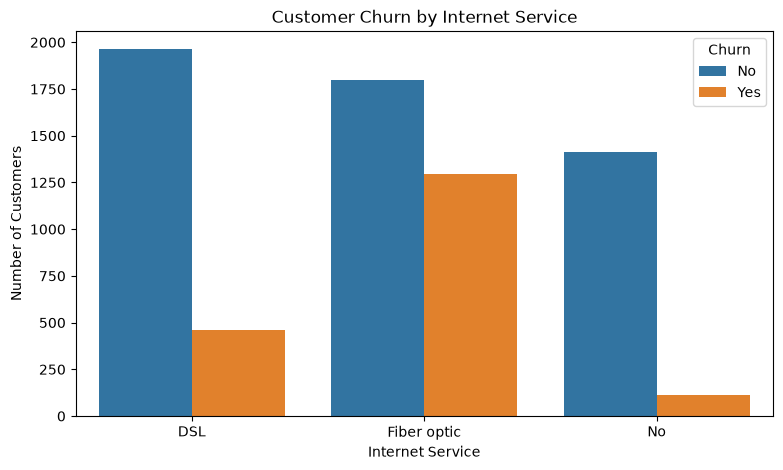

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [33]:
churn_rate_by_feature(df, "InternetService")

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


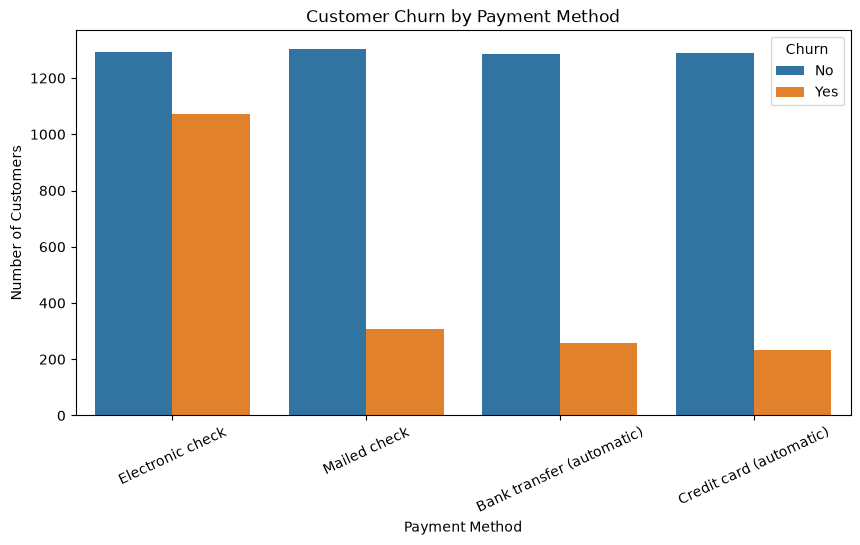

In [34]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25)

plt.show()

In [ ]:
#Which services are associated with lower/higher churn?
service_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]
for feature in service_features:
    print(f"\n===== {feature} =====")
    print(churn_rate_by_feature(df, feature))


===== OnlineSecurity =====
Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194

===== OnlineBackup =====
Churn                       No        Yes
OnlineBackup                             
No                   60.071244  39.928756
No internet service  92.595020   7.404980
Yes                  78.468506  21.531494

===== DeviceProtection =====
Churn                       No        Yes
DeviceProtection                         
No                   60.872375  39.127625
No internet service  92.595020   7.404980
Yes                  77.497936  22.502064

===== TechSupport =====
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341

===== StreamingTV =====
Churn                     

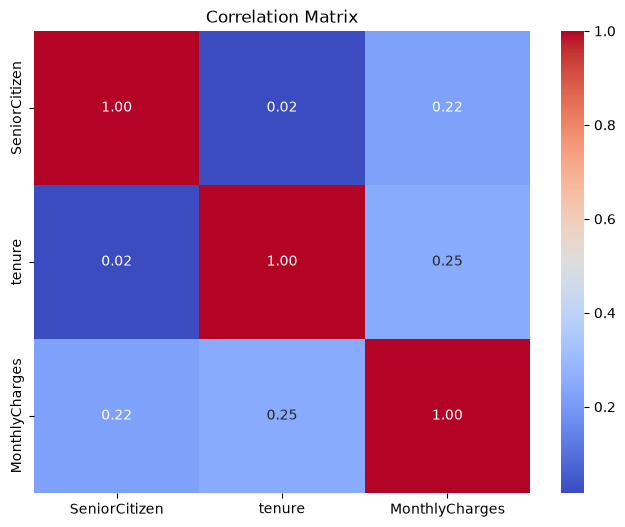

In [ ]:
#Correlation Analysis
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]
df[numeric_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

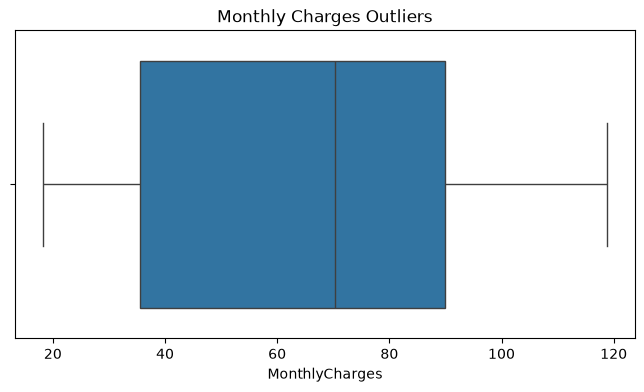

In [ ]:
#Outlier Analysis
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df["MonthlyCharges"]
)

plt.title("Monthly Charges Outliers")
plt.show()

In [ ]:
#Data Quality Summary
data_quality = pd.DataFrame({
    "Column": df.columns,
    "DataType": df.dtypes.astype(str).values,
    "MissingValues": df.isnull().sum().values,
    "UniqueValues": df.nunique().values
})

data_quality

,Column,DataType,MissingValues,UniqueValues
0,customerID,str,0,7043
1,gender,str,0,2
2,SeniorCitizen,int64,0,2
3,Partner,str,0,2
4,Dependents,str,0,2
5,tenure,int64,0,73
6,PhoneService,str,0,2
7,MultipleLines,str,0,3
8,InternetService,str,0,3
9,OnlineSecurity,str,0,3


# Key Findings

## Customer Churn

Approximately 26.5% of customers have churned.

## Customer Tenure

Customers with shorter tenure appear to have a higher churn rate.

## Contract

Month-to-month customers appear to have substantially higher
churn rates than customers with longer-term contracts.

## Monthly Charges

Customers with higher monthly charges appear to show different
churn behavior compared with customers with lower charges.

## Services

Certain service combinations appear to be associated with
different churn rates.

## Payment Method

Churn rates vary across payment methods.

## Data Quality

`TotalCharges` requires conversion from string/object to a
numeric representation before machine learning.

## Modeling Implication

The target variable is imbalanced. Therefore, model evaluation
should consider precision, recall, F1-score and ROC-AUC rather
than accuracy alone.

# Business Hypotheses

### H1 — Contract

Customers on month-to-month contracts are more likely to churn.

### H2 — Tenure

Customers with shorter tenure are more likely to churn.

### H3 — Monthly Charges

Customers with higher monthly charges may have a higher churn risk.

### H4 — Services

Customers without additional support/security services may have
different churn behavior.

### H5 — Payment Method

Churn behavior may vary by payment method.